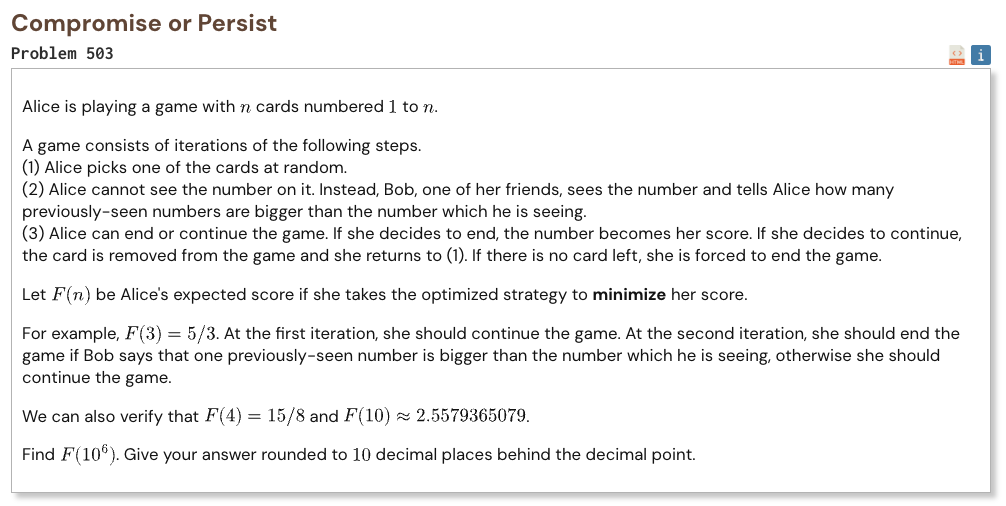

## Initial approach

- treat the revealed order information as a relative rank among the cards seen so far
- each possible relative rank is equally likely at every turn
- calculate the expected card value for each possible rank
- compare stopping now with the expected value of continuing
- work backwards from the final forced turn using dynamic programming
- use a threshold so all possible ranks can be handled in constant time per turn

In [1]:
%%time

N = 1_000_000

value = (N + 1) / 2

for turn in range(N - 1, 0, -1):
    threshold = int(
        value * (turn + 1) / (N + 1)
    )

    threshold = min(threshold, turn)

    stop_total = (
        (N + 1)
        * threshold
        * (threshold + 1)
        / (2 * (turn + 1))
    )

    continue_total = (
        turn - threshold
    ) * value

    value = (
        stop_total + continue_total
    ) / turn

result = value

print("Result:", f"{result:.10f}")

Result: 3.8694550145
CPU times: user 382 ms, sys: 1.49 ms, total: 384 ms
Wall time: 384 ms
